

- ability to specify river, treatment, time period (relative to start of trial, relative to treatment), trial; look at a time series of [quantity], look at a histogram of [quantity]
- way to assess how long it takes to acclimate/settles down. how do we quantify that
- 

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

VIDEO_FOLDER = "/home/bw/Projects/c02-fish/Videos"
pd.set_option('display.max_columns', None)

In [4]:
DATA_FOLDER = "tracking_output/"

In [5]:
dfs = []
for river in ["Green", "Skagit"]:
    for pH in [1, 2, 3]:
        for trial in range(1, 11):
            # DATA_FOLDER = VIDEO_FOLDER + f"/River-{river}/pH-{pH}/Trial-{trial}/data/"
            for individual in range(0, 6):
                try:
                    indiv = pd.read_csv(DATA_FOLDER + f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}.csv")
                    indiv["River"] = river
                    indiv["pH"] = pH
                    indiv["Trial"] = trial
                    indiv["Individual"] = individual
                    dfs.append(indiv)
                except:
                    print("skipping", f"River-{river}-pH-{pH}-Trial-{trial}_id{individual}")

skipping River-Green-pH-2-Trial-2_id0
skipping River-Green-pH-2-Trial-2_id1
skipping River-Green-pH-2-Trial-2_id2
skipping River-Green-pH-2-Trial-2_id3
skipping River-Green-pH-2-Trial-2_id4
skipping River-Green-pH-2-Trial-2_id5
skipping River-Skagit-pH-1-Trial-9_id2
skipping River-Skagit-pH-1-Trial-9_id4
skipping River-Skagit-pH-2-Trial-2_id0
skipping River-Skagit-pH-2-Trial-5_id0
skipping River-Skagit-pH-2-Trial-5_id1
skipping River-Skagit-pH-2-Trial-5_id2
skipping River-Skagit-pH-2-Trial-5_id3
skipping River-Skagit-pH-2-Trial-5_id4
skipping River-Skagit-pH-2-Trial-5_id5
skipping River-Skagit-pH-2-Trial-6_id0
skipping River-Skagit-pH-2-Trial-6_id1
skipping River-Skagit-pH-2-Trial-6_id2
skipping River-Skagit-pH-2-Trial-6_id3
skipping River-Skagit-pH-2-Trial-6_id4
skipping River-Skagit-pH-2-Trial-6_id5
skipping River-Skagit-pH-2-Trial-7_id0
skipping River-Skagit-pH-2-Trial-7_id1
skipping River-Skagit-pH-2-Trial-7_id2
skipping River-Skagit-pH-2-Trial-7_id3
skipping River-Skagit-pH-2-Tria

In [6]:
df = pd.concat(dfs, ignore_index=True)

In [8]:
# sns.relplot(data=df, col="River", 

In [17]:
df.to_csv("trek_output.csv")

<Axes: xlabel='time', ylabel='SPEED (cm/s)'>

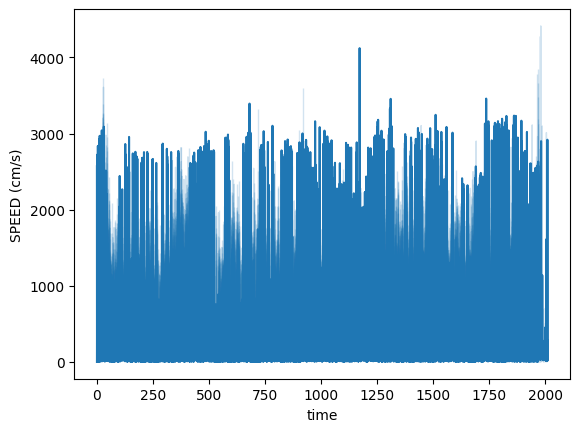

In [10]:
_df = df[
    (df["River"] == "Green") &
    (df["pH"] == 1) &
    (df["Individual"] == 0)]
sns.lineplot(data=_df, x="time", y="SPEED (cm/s)")

In [14]:
df.columns

Index(['frame', 'ACCELERATION#pcentroid (cm/s2)',
       'ACCELERATION#wcentroid (cm/s2)', 'ANGLE', 'ANGULAR_A#centroid',
       'ANGULAR_V#centroid', 'AX', 'AY', 'BORDER_DISTANCE#pcentroid (cm)',
       'MIDLINE_OFFSET', 'SPEED#wcentroid (cm/s)', 'SPEED#pcentroid (cm/s)',
       'SPEED (cm/s)', 'VX (cm/s)', 'VY (cm/s)', 'X#wcentroid (cm)', 'X (cm)',
       'Y#wcentroid (cm)', 'Y (cm)', 'detection_p', 'frame.1',
       'midline_length', 'midline_segment_length', 'midline_x', 'midline_y',
       'missing', 'normalized_midline', 'num_pixels', 'time', 'timestamp',
       'visual_identification_p', 'River', 'pH', 'Trial', 'Individual',
       'ANGULAR_A', 'ANGULAR_V'],
      dtype='object')

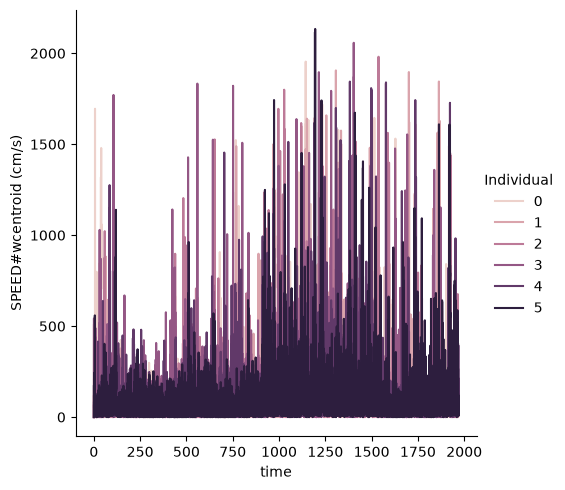

In [38]:
sns.relplot(data=df, x="time", y="SPEED#wcentroid (cm/s)", hue="Individual", kind="line")

In [11]:
30 * 60

1800

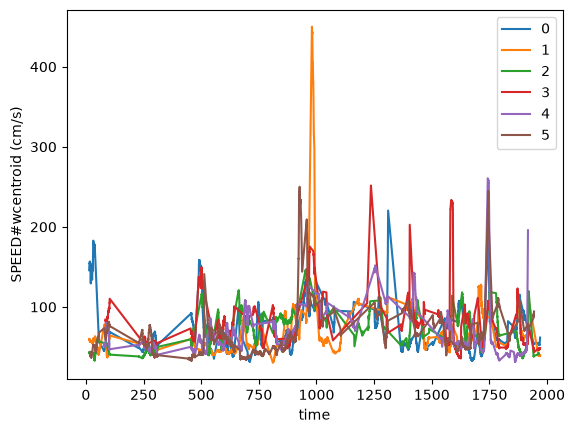

In [61]:
ROLLING = 200
VAL = "SPEED#wcentroid (cm/s)"
for indiv in range(6):
    _df = df[df["Individual"] == indiv]
    sns.lineplot(y=_df[VAL].rolling(ROLLING).mean(), x=_df["time"], label=indiv)

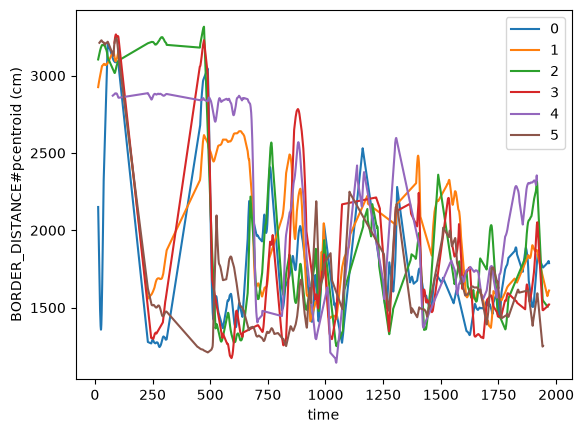

In [65]:
ROLLING = 200
VAL = "BORDER_DISTANCE#pcentroid (cm)"
for indiv in range(6):
    _df = df[df["Individual"] == indiv]
    sns.lineplot(y=_df[VAL].rolling(ROLLING).mean(), x=_df["time"], label=indiv)

In [63]:
df.columns

Index(['frame', 'ACCELERATION#pcentroid (cm/s2)',
       'ACCELERATION#wcentroid (cm/s2)', 'ANGLE', 'ANGULAR_A#centroid',
       'ANGULAR_V#centroid', 'AX', 'AY', 'BORDER_DISTANCE#pcentroid (cm)',
       'MIDLINE_OFFSET', 'SPEED#wcentroid (cm/s)', 'SPEED#pcentroid (cm/s)',
       'SPEED (cm/s)', 'VX (cm/s)', 'VY (cm/s)', 'X#wcentroid (cm)', 'X (cm)',
       'Y#wcentroid (cm)', 'Y (cm)', 'detection_p', 'frame.1',
       'midline_length', 'midline_segment_length', 'midline_x', 'midline_y',
       'missing', 'normalized_midline', 'num_pixels', 'time', 'timestamp',
       'visual_identification_p', 'River', 'pH', 'Trial', 'Individual'],
      dtype='str')